# Credit Risk Assessment — Clean End-to-End Notebook

This notebook trains, validates, calibrates, evaluates, and exports one credit-risk model for the FastAPI application.

**Important rules built into this notebook**
- Split data into train, validation, and test sets before preprocessing.
- Fit preprocessing only inside pipelines.
- Tune the model using training data only.
- Choose the classification threshold using validation data only.
- Use the test set once for final evaluation, after the model and threshold are fixed.
- Export one model file and one matching threshold file.

## 1. Install and import libraries

Run this cell in Google Colab. Restart the runtime only if Colab explicitly asks you to.

In [1]:
!pip -q install xgboost==3.4.1 joblib==1.6.0


In [2]:
import os
import json
import hashlib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost
import joblib

from google.colab import files

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, precision_recall_curve, RocCurveDisplay
)
from xgboost import XGBClassifier
from scipy.stats import randint, uniform

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Python environment ready")
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)
print("joblib:", joblib.__version__)

Python environment ready
pandas: 2.2.3
scikit-learn: 1.6.1
XGBoost: 3.4.1
joblib: 1.6.0


## 2. Load the dataset

Upload `credit_risk_dataset.csv` when prompted. This is the dataset used in the earlier notebook. If your CSV has a different name, the code still loads the first uploaded CSV.

In [3]:
uploaded = files.upload()
csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]

if not csv_files:
    raise FileNotFoundError("Upload a CSV file, preferably credit_risk_dataset.csv")

DATA_PATH = csv_files[0]
df = pd.read_csv(DATA_PATH)

print("Loaded:", DATA_PATH)
print("Shape:", df.shape)
display(df.head())

Saving credit_risk_dataset.csv to credit_risk_dataset (1).csv
Loaded: credit_risk_dataset (1).csv
Shape: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


## 3. Inspect and validate the data

In [4]:
print(df.info())
display(df.isnull().sum().sort_values(ascending=False).to_frame("missing_values"))
display(df["loan_status"].value_counts(dropna=False).to_frame("count"))

if "loan_status" not in df.columns:
    raise ValueError("Target column 'loan_status' is missing.")

if df["loan_status"].isna().any():
    raise ValueError("Target column contains missing values. Inspect and resolve them before training.")

target_values = set(df["loan_status"].unique())
if not target_values.issubset({0, 1}):
    raise ValueError(f"Expected binary target values 0 and 1, found: {target_values}")

display(df.describe(include="all").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB
None


,missing_values
loan_int_rate,3116
person_emp_length,895
person_income,0
person_age,0
person_home_ownership,0
loan_intent,0
loan_grade,0
loan_amnt,0
loan_status,0
loan_percent_income,0


,count
loan_status,
0,25473
1,7108


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
person_age,32581.0,NaN,NaN,NaN,27.7346,6.348078,20.0,23.0,26.0,30.0,144.0
person_income,32581.0,NaN,NaN,NaN,66074.84847,61983.119168,4000.0,38500.0,55000.0,79200.0,6000000.0
person_home_ownership,32581,4,RENT,16446,NaN,NaN,NaN,NaN,NaN,NaN,NaN
person_emp_length,31686.0,NaN,NaN,NaN,4.789686,4.14263,0.0,2.0,4.0,7.0,123.0
loan_intent,32581,6,EDUCATION,6453,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan_grade,32581,7,A,10777,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan_amnt,32581.0,NaN,NaN,NaN,9589.371106,6322.086646,500.0,5000.0,8000.0,12200.0,35000.0
loan_int_rate,29465.0,NaN,NaN,NaN,11.011695,3.240459,5.42,7.9,10.99,13.47,23.22
loan_status,32581.0,NaN,NaN,NaN,0.218164,0.413006,0.0,0.0,0.0,0.0,1.0
loan_percent_income,32581.0,NaN,NaN,NaN,0.170203,0.106782,0.0,0.09,0.15,0.23,0.83


## 4. Clean the data

The cleaning rules below preserve the rules used in your previous notebook:
- Remove duplicate rows.
- Keep ages from 18 through 99.
- Remove employment lengths above 60 years or greater than age.
- Keep positive loan amounts.

Do not silently change these rules without checking the dataset and documenting why.

In [5]:
df = df.copy()
rows_before = len(df)

df = df.drop_duplicates()
df = df[df["person_age"].between(18, 99)]
df = df[df["person_emp_length"].notna() | df["person_emp_length"].isna()]
df = df[(df["person_emp_length"].isna()) | (df["person_emp_length"] <= 60)]
df = df[(df["person_emp_length"].isna()) | (df["person_emp_length"] <= df["person_age"])]
df = df[df["loan_amnt"] > 0]

print(f"Rows before cleaning: {rows_before:,}")
print(f"Rows after cleaning:  {len(df):,}")
print(f"Rows removed:         {rows_before - len(df):,}")
print("Target distribution:")
display(df["loan_status"].value_counts(normalize=True).rename("proportion").to_frame())

Rows before cleaning: 32,581
Rows after cleaning:  32,409
Rows removed:         172
Target distribution:


,proportion
loan_status,
0,0.781295
1,0.218705


## 5. Define features and target

Class `1` is treated as loan default / higher risk. Class `0` is treated as non-default / lower risk.

In [6]:
TARGET = "loan_status"

numeric_cols = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income",
    "cb_person_cred_hist_length",
]

categorical_cols = [
    "person_home_ownership",
    "loan_intent",
    "loan_grade",
    "cb_person_default_on_file",
]

required_cols = numeric_cols + categorical_cols + [TARGET]
missing_cols = [col for col in required_cols if col not in df.columns]
if missing_cols:
    raise ValueError(f"Dataset is missing required columns: {missing_cols}")

X = df[numeric_cols + categorical_cols].copy()
y = df[TARGET].astype(int).copy()

print("Features:", X.shape[1])
print("Rows:", X.shape[0])
print("Class counts:")
display(y.value_counts().sort_index().to_frame("count"))

Features: 11
Rows: 32409
Class counts:


,count
loan_status,
0,25321
1,7088


## 6. Split into train, validation, and test sets

The test set is held back until the very end. Do not use `X_test` or `y_test` to tune hyperparameters, calibrate probabilities, or select the threshold.

In [7]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.20, random_state=RANDOM_STATE, stratify=y_train_val
)

print("Train:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)
print("Train default rate:", round(y_train.mean(), 4))
print("Validation default rate:", round(y_val.mean(), 4))
print("Test default rate:", round(y_test.mean(), 4))

Train: (20741, 11) Validation: (5186, 11) Test: (6482, 11)
Train default rate: 0.2187
Validation default rate: 0.2187
Test default rate: 0.2188


## 7. Build preprocessing and baseline model

Missing-value imputation and one-hot encoding are inside the pipeline. This prevents preprocessing leakage and ensures the same transformations are applied in the API.

In [8]:
numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_preprocessor, numeric_cols),
        ("cat", categorical_preprocessor, categorical_cols),
    ],
    remainder="drop",
)

baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1500,
        class_weight="balanced",
        random_state=RANDOM_STATE
    )),
])

baseline_model.fit(X_train, y_train)
baseline_val_prob = baseline_model.predict_proba(X_val)[:, 1]

print("Baseline validation ROC-AUC:", round(roc_auc_score(y_val, baseline_val_prob), 4))
print("Baseline validation average precision:", round(average_precision_score(y_val, baseline_val_prob), 4))

Baseline validation ROC-AUC: 0.8585
Baseline validation average precision: 0.6897


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## 8. Calculate class imbalance and build XGBoost pipeline

In [9]:
class_counts = y_train.value_counts()
neg = int(class_counts.get(0, 0))
pos = int(class_counts.get(1, 0))
if pos == 0:
    raise ValueError("Training data contains no positive/default cases.")

scale_pos_weight = neg / pos
print("Negative cases:", neg)
print("Positive/default cases:", pos)
print("scale_pos_weight:", round(scale_pos_weight, 4))

xgb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        n_jobs=-1,
        random_state=RANDOM_STATE,
        scale_pos_weight=scale_pos_weight,
    )),
])

Negative cases: 16205
Positive/default cases: 4536
scale_pos_weight: 3.5725


## 9. Hyperparameter tuning — training set only

RandomizedSearchCV sees only `X_train` and `y_train`. The validation set remains separate for calibration threshold selection.

In [10]:
param_distributions = {
    "classifier__n_estimators": randint(150, 501),
    "classifier__max_depth": randint(3, 9),
    "classifier__learning_rate": uniform(0.02, 0.18),
    "classifier__subsample": uniform(0.70, 0.30),
    "classifier__colsample_bytree": uniform(0.70, 0.30),
    "classifier__min_child_weight": randint(1, 10),
    "classifier__gamma": uniform(0.0, 3.0),
    "classifier__reg_lambda": uniform(0.5, 5.0),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_distributions,
    n_iter=20,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    random_state=RANDOM_STATE,
    refit=True,
)

random_search.fit(X_train, y_train)

best_model = random_search.best_estimator_
print("Best CV ROC-AUC:", round(random_search.best_score_, 4))
print("Best parameters:")
print(random_search.best_params_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best CV ROC-AUC: 0.9447
Best parameters:
{'classifier__colsample_bytree': np.float64(0.9526854323784995), 'classifier__gamma': np.float64(1.349262400109297), 'classifier__learning_rate': np.float64(0.0911270424803266), 'classifier__max_depth': 6, 'classifier__min_child_weight': 8, 'classifier__n_estimators': 364, 'classifier__reg_lambda': np.float64(3.1041713001291185), 'classifier__subsample': np.float64(0.9883516073048046)}


## 10. Probability calibration

Calibration is fitted using training data only. Sigmoid calibration is selected as the single final calibration method for this notebook.

In [11]:
calibrated_model = CalibratedClassifierCV(
    estimator=best_model,
    method="sigmoid",
    cv=5,
)

calibrated_model.fit(X_train, y_train)

train_prob = calibrated_model.predict_proba(X_train)[:, 1]
val_prob = calibrated_model.predict_proba(X_val)[:, 1]

print("Validation ROC-AUC:", round(roc_auc_score(y_val, val_prob), 4))
print("Validation average precision:", round(average_precision_score(y_val, val_prob), 4))

Validation ROC-AUC: 0.9481
Validation average precision: 0.8991


## 11. Select threshold using validation data only

This notebook uses maximum validation F1 as a transparent starting rule. In real lending, the threshold should ultimately reflect the relative financial cost of approving a defaulter versus rejecting a good borrower.

In [12]:
precisions, recalls, thresholds = precision_recall_curve(y_val, val_prob)

# precision_recall_curve returns one more precision/recall point than thresholds.
f1_values = (
    2 * precisions[:-1] * recalls[:-1]
    / (precisions[:-1] + recalls[:-1] + 1e-12)
)

if len(thresholds) == 0:
    raise ValueError("Could not calculate validation thresholds.")

best_idx = int(np.nanargmax(f1_values))
best_threshold = float(thresholds[best_idx])

val_pred = (val_prob >= best_threshold).astype(int)

print("Selected validation threshold:", round(best_threshold, 6))
print("Validation accuracy:", round(accuracy_score(y_val, val_pred), 4))
print("Validation precision:", round(precision_score(y_val, val_pred, zero_division=0), 4))
print("Validation recall:", round(recall_score(y_val, val_pred, zero_division=0), 4))
print("Validation F1:", round(f1_score(y_val, val_pred, zero_division=0), 4))
print("Validation confusion matrix:")
print(confusion_matrix(y_val, val_pred))

Selected validation threshold: 0.609281
Validation accuracy: 0.9312
Validation precision: 0.946
Validation recall: 0.7266
Validation F1: 0.8219
Validation confusion matrix:
[[4005   47]
 [ 310  824]]


## 12. Inspect threshold trade-offs

Use this to understand the precision/recall trade-off. Do not select a new threshold after looking at the test set.

In [13]:
threshold_rows = []
for t in [0.20, 0.30, 0.40, 0.50, best_threshold, 0.60, 0.70, 0.80]:
    pred = (val_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred, labels=[0, 1]).ravel()
    threshold_rows.append({
        "threshold": float(t),
        "precision": precision_score(y_val, pred, zero_division=0),
        "recall": recall_score(y_val, pred, zero_division=0),
        "f1": f1_score(y_val, pred, zero_division=0),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_positives": int(tp),
        "true_negatives": int(tn),
    })

threshold_table = pd.DataFrame(threshold_rows).drop_duplicates(subset=["threshold"])
display(threshold_table.sort_values("threshold").round(4))

,threshold,precision,recall,f1,false_positives,false_negatives,true_positives,true_negatives
0,0.2000,0.7173,0.8210,0.7656,367,203,931,3685
1,0.3000,0.8016,0.7945,0.7981,223,233,901,3829
2,0.4000,0.8657,0.7672,0.8135,135,264,870,3917
3,0.5000,0.9056,0.7443,0.8170,88,290,844,3964
5,0.6000,0.9417,0.7266,0.8203,51,310,824,4001
4,0.6093,0.9460,0.7266,0.8219,47,310,824,4005
6,0.7000,0.9722,0.7090,0.8200,23,330,804,4029
7,0.8000,0.9835,0.6852,0.8077,13,357,777,4039


## 13. Final test evaluation — do this only after model and threshold are fixed

This is the first point where the test labels are used for model evaluation. Do not change the model, calibration method, or threshold based on these results.

In [14]:
test_prob = calibrated_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= best_threshold).astype(int)

print("FINAL TEST RESULTS")
print("Threshold:", round(best_threshold, 6))
print("ROC-AUC:", round(roc_auc_score(y_test, test_prob), 4))
print("Average precision:", round(average_precision_score(y_test, test_prob), 4))
print("Accuracy:", round(accuracy_score(y_test, test_pred), 4))
print("Precision:", round(precision_score(y_test, test_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, test_pred, zero_division=0), 4))
print("F1:", round(f1_score(y_test, test_pred, zero_division=0), 4))
print("\nClassification report:")
print(classification_report(y_test, test_pred, zero_division=0))
print("Confusion matrix:")
print(confusion_matrix(y_test, test_pred))

FINAL TEST RESULTS
Threshold: 0.609281
ROC-AUC: 0.9517
Average precision: 0.9085
Accuracy: 0.9378
Precision: 0.9503
Recall: 0.7553
F1: 0.8417

Classification report:
              precision    recall  f1-score   support

           0       0.94      0.99      0.96      5064
           1       0.95      0.76      0.84      1418

    accuracy                           0.94      6482
   macro avg       0.94      0.87      0.90      6482
weighted avg       0.94      0.94      0.94      6482

Confusion matrix:
[[5008   56]
 [ 347 1071]]


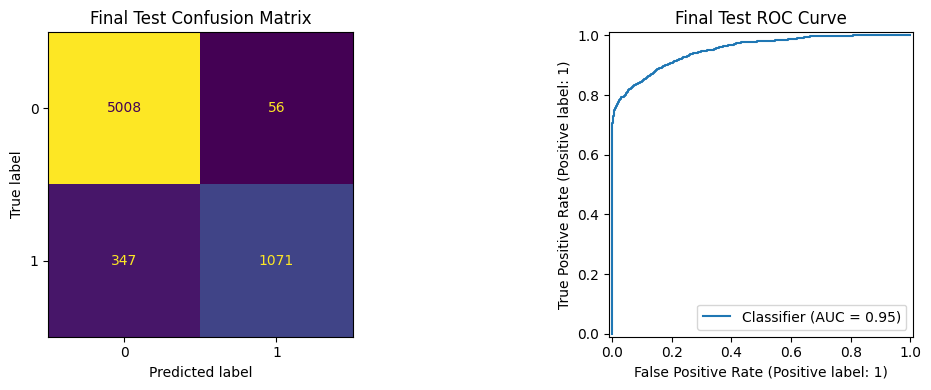

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ConfusionMatrixDisplay = __import__(
    "sklearn.metrics", fromlist=["ConfusionMatrixDisplay"]
).ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, ax=axes[0], colorbar=False)
axes[0].set_title("Final Test Confusion Matrix")

RocCurveDisplay.from_predictions(y_test, test_prob, ax=axes[1])
axes[1].set_title("Final Test ROC Curve")

plt.tight_layout()
plt.show()

## 14. Calibration curve on the held-out test set

This is diagnostic reporting only. Do not use it to retune the model or threshold.

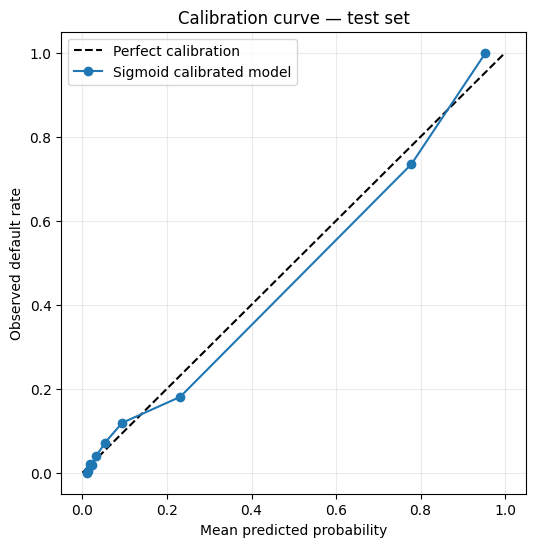

In [16]:
actual_rate, mean_predicted = calibration_curve(
    y_test, test_prob, n_bins=10, strategy="quantile"
)

plt.figure(figsize=(6, 6))
plt.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
plt.plot(mean_predicted, actual_rate, "o-", label="Sigmoid calibrated model")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed default rate")
plt.title("Calibration curve — test set")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 15. Export one final model and one matching threshold

These filenames match the FastAPI `main.py` provided separately:
- `credit_risk_model_new.pkl`
- `best_threshold_new.pkl`

The verification below reloads the artifacts and checks that reloaded predictions match the in-memory model.

In [17]:
MODEL_PATH = "credit_risk_model_new.pkl"
THRESHOLD_PATH = "best_threshold_new.pkl"

joblib.dump(calibrated_model, MODEL_PATH, compress=0)
joblib.dump(float(best_threshold), THRESHOLD_PATH)

reloaded_model = joblib.load(MODEL_PATH)
reloaded_threshold = float(joblib.load(THRESHOLD_PATH))

sample = X_val.iloc[:10].copy()
pred_before = calibrated_model.predict_proba(sample)[:, 1]
pred_after = reloaded_model.predict_proba(sample)[:, 1]

assert np.allclose(pred_before, pred_after, rtol=1e-7, atol=1e-9), "Reloaded model predictions differ!"
assert np.isclose(reloaded_threshold, best_threshold), "Threshold mismatch!"
assert 0 < reloaded_threshold < 1, "Threshold is outside (0, 1)."

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

print("EXPORT VERIFIED")
print("Model file size:", os.path.getsize(MODEL_PATH), "bytes")
print("Threshold:", reloaded_threshold)
print("Model SHA256:", sha256_file(MODEL_PATH))
print("Threshold SHA256:", sha256_file(THRESHOLD_PATH))
print("scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)
print("joblib:", joblib.__version__)

EXPORT VERIFIED
Model file size: 3668950 bytes
Threshold: 0.6092805517702241
Model SHA256: 7bf922198cb915ba0945b73662138dcf88e74810a9ca1c085f4c876aac9af334
Threshold SHA256: 0cd8c7a1cedff21d0d4fa154b03972992e6ff0f3021f40c9f636da330af06965
scikit-learn: 1.6.1
XGBoost: 3.4.1
joblib: 1.6.0


## 16. Download the final artifacts

Download both files and put them in the same local folder as `main.py`.

In [18]:
files.download(MODEL_PATH)
files.download(THRESHOLD_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 17. Final checklist

- [ ] The CSV loaded successfully and contains the required feature columns.
- [ ] The model trained without errors.
- [ ] The threshold was selected using validation data (`X_val`, `y_val`), not test data.
- [ ] Final test metrics were reported only after the threshold was fixed.
- [ ] The export verification passed.
- [ ] Both `.pkl` files were downloaded from this same notebook run.
- [ ] The local API environment uses the same scikit-learn, XGBoost, and joblib versions printed in the export cell.

**Do not mix model and threshold files from different notebook runs.**